In [2]:
import kagglehub

# Download latest version
output_dir='./data'
path = kagglehub.dataset_download("blastchar/telco-customer-churn",output_dir=output_dir)

print("Path to dataset files:", path)

100%|██████████| 172k/172k [00:00<00:00, 198kB/s]

Extracting files...
Path to dataset files: ./data


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ydata_profiling import ProfileReport

df = pd.read_csv('./data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.describe(include='all'))

report = ProfileReport(
    df,
    title="Pandas Profiling Report",
    explorative=True
)

report.to_file("EDA_report.html")

        customerID gender  SeniorCitizen Partner Dependents       tenure  \
count         7043   7043    7043.000000    7043       7043  7043.000000   
unique        7043      2            NaN       2          2          NaN   
top     3186-AJIEK   Male            NaN      No         No          NaN   
freq             1   3555            NaN    3641       4933          NaN   
mean           NaN    NaN       0.162147     NaN        NaN    32.371149   
std            NaN    NaN       0.368612     NaN        NaN    24.559481   
min            NaN    NaN       0.000000     NaN        NaN     0.000000   
25%            NaN    NaN       0.000000     NaN        NaN     9.000000   
50%            NaN    NaN       0.000000     NaN        NaN    29.000000   
75%            NaN    NaN       0.000000     NaN        NaN    55.000000   
max            NaN    NaN       1.000000     NaN        NaN    72.000000   

       PhoneService MultipleLines InternetService OnlineSecurity  ...  \
count         

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 59.49it/s]


In [3]:
print(df.describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000


In [4]:
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

C:\Users\mahad\AppData\Local\Temp\ipykernel_5872\2657664157.py:3: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

df.drop(columns=['customerID'], inplace=True)   



In [6]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [8]:
x=df.drop(columns=['Churn'])
y=df['Churn']

numerical_features=x.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features=x.select_dtypes(include=['object']).columns.to_list()

x_train,x_temp,y_train,y_temp=train_test_split(x,y,test_size=0.3,random_state=42,stratify=y)
x_val,x_test,y_val,y_test=train_test_split(x_temp,y_temp,test_size=0.5,random_state=42,stratify=y_temp)

numerical_transformer=Pipeline([('imputer',SimpleImputer(strategy='median')),("scaler", StandardScaler())])
categorcal_transformer=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('encoder',OneHotEncoder(handle_unknown='ignore'))])

preprocessor=ColumnTransformer(transformers=[('num',numerical_transformer,numerical_features),('cat',categorcal_transformer,categorical_features)])

x_train=preprocessor.fit_transform(x_train)
x_val=preprocessor.transform(x_val)
x_test=preprocessor.transform(x_test)

x_train=x_train.toarray() if hasattr(x_train, "toarray") else x_train
x_val=x_val.toarray() if hasattr(x_val, "toarray") else x_val
x_test=x_test.toarray() if hasattr(x_test, "toarray") else x_test

print("Training shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Testing shape:", x_test.shape)

Training shape: (4930, 45)
Validation shape: (1056, 45)
Testing shape: (1057, 45)


In [11]:
import torch
from torch.utils.data import Dataset,DataLoader,TensorDataset

x_train_tensor=torch.tensor(x_train,dtype=torch.float32)
x_val_tensor=torch.tensor(x_val,dtype=torch.float32)
x_test_tensor=torch.tensor(x_test,dtype=torch.float32)

y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_val_tensor=torch.tensor(y_val.values,dtype=torch.float32).view(-1,1)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

train_dataset=TensorDataset(x_train_tensor,y_train_tensor)
val_dataset=TensorDataset(x_val_tensor,y_val_tensor)
test_dataset=TensorDataset(x_test_tensor,y_test_tensor)

train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=32,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=32,shuffle=False)

In [15]:
import torch.nn as nn

class ChurnModel(nn.Module):

    def __init__(self,input_features):
        super(ChurnModel,self).__init__()

        self.network=nn.Sequential(
            nn.Linear(input_features,64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64,32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32,1)
        )

    def forward(self,x):
        return self.network(x)

In [16]:
input_features=x_train_tensor.shape[1]
model=ChurnModel(input_features)
print(model)

ChurnModel(
  (network): Sequential(
    (0): Linear(in_features=45, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [17]:
import torch.optim as optim

positive_count=y_train.sum()
negative_count=len(y_train)-positive_count

pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Positive weight:", pos_weight.item())

Positive weight: 2.769113063812256


In [21]:
epochs=100

train_losses=[]
val_losses=[]

for epoch in range(epochs):
    model.train()
    running_loss=0

    for x_batch,y_batch in train_loader:
        outputs=model(x_batch)
        loss=criterion(outputs,y_batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss+=loss.item()

    epoch_train_loss=running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    model.eval()
    val_loss=0

    with torch.no_grad():
        for x_batch,y_batch in val_loader:
            outputs=model(x_batch)
            loss=criterion(outputs,y_batch)
            val_loss+=loss.item()
            
    epoch_val_loss=val_loss/len(val_loader)

    val_losses.append(epoch_val_loss)

    if(epoch+1)%10==0:
        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {epoch_train_loss:.4f} "
            f"Val Loss: {epoch_val_loss:.4f}"
        )

Epoch [10/100] Train Loss: 0.7089 Val Loss: 0.7241
Epoch [20/100] Train Loss: 0.6920 Val Loss: 0.7245
Epoch [30/100] Train Loss: 0.6737 Val Loss: 0.7292
Epoch [40/100] Train Loss: 0.6586 Val Loss: 0.7373
Epoch [50/100] Train Loss: 0.6278 Val Loss: 0.7663
Epoch [60/100] Train Loss: 0.6267 Val Loss: 0.7810
Epoch [70/100] Train Loss: 0.6159 Val Loss: 0.7830
Epoch [80/100] Train Loss: 0.5927 Val Loss: 0.7994
Epoch [90/100] Train Loss: 0.5998 Val Loss: 0.8120
Epoch [100/100] Train Loss: 0.5825 Val Loss: 0.8193


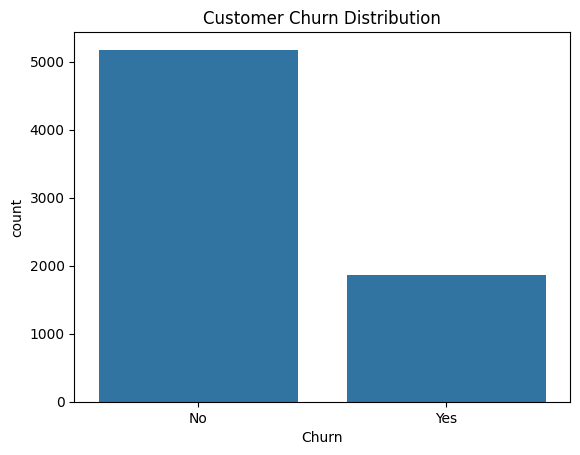

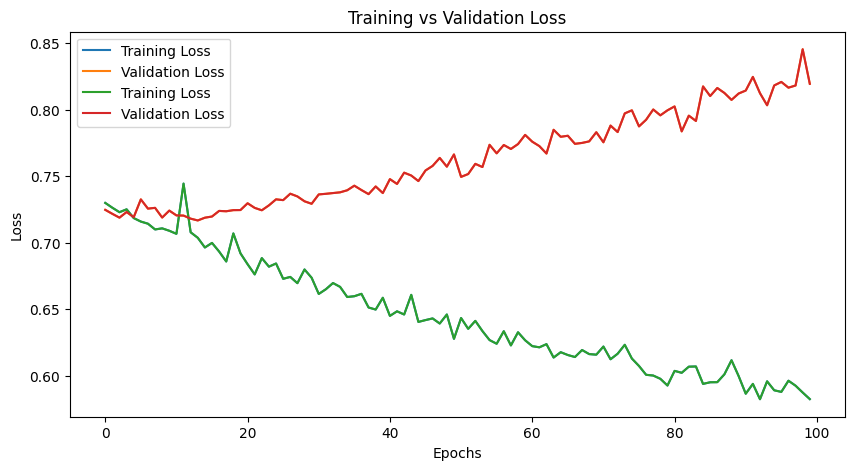

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

model.eval()

with torch.no_grad():
    logits=model(x_test_tensor)
    probabilities=torch.sigmoid(logits).numpy().ravel()
    predictions=(probabilities>=0.5).astype(int)

actual=y_test.values

# Evaluation metrics
print("Accuracy:", accuracy_score(actual, predictions))

print("Precision:", precision_score(actual, predictions))

print("Recall:", recall_score(actual, predictions))

print("F1 Score:", f1_score(actual, predictions))

print("ROC-AUC:", roc_auc_score(actual, probabilities))

print("\nClassification Report:\n")

print(classification_report(
    actual,
    predictions,
    target_names=["Not Churn", "Churn"]
))


Accuracy: 0.750236518448439
Precision: 0.5204819277108433
Recall: 0.7686832740213523
F1 Score: 0.6206896551724138
ROC-AUC: 0.8261616282055985

Classification Report:

              precision    recall  f1-score   support

   Not Churn       0.90      0.74      0.81       776
       Churn       0.52      0.77      0.62       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.76      1057



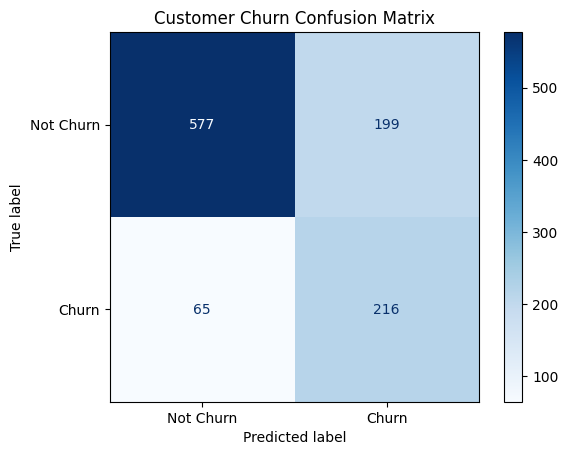

In [25]:
cm = confusion_matrix(actual, predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

disp.plot(cmap="Blues")

plt.title("Customer Churn Confusion Matrix")

plt.show()

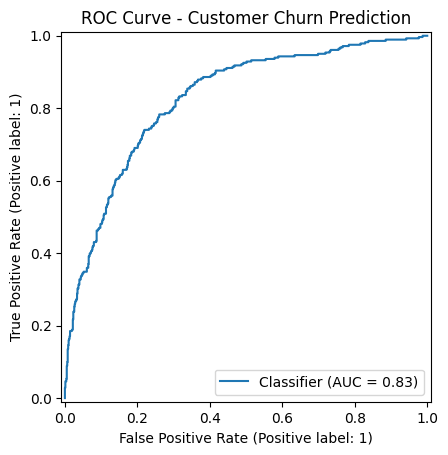

In [26]:
RocCurveDisplay.from_predictions(
    actual,
    probabilities
)

plt.title("ROC Curve - Customer Churn Prediction")

plt.show()

In [27]:
import os
import joblib

os.makedirs('models', exist_ok=True)
torch.save({'model_state_dict': model.state_dict(),'input_features':input_features},'models/churn_model.pth')
joblib.dump({"preprocessor": preprocessor,"feature_columns": x.columns.tolist()}, "models/preprocessing.pkl")
print("Model and preprocessing pipeline saved!")

Model and preprocessing pipeline saved!
